## NB11 — Validação com Dados Sintéticos

**Entrada:** `data/load/dataset_ml_model.csv` — 75.471 linhas × 26 colunas  
**Saída:** `data/output/recall_sinteticos.csv` — recall por modelo e perfil de anomalia

---
### 0. Imports e Configuração

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import MinMaxScaler, StandardScaler

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')

RANDOM_STATE  = 42
CONTAMINATION = 0.01
N_SINTETICOS  = 2500

np.random.seed(RANDOM_STATE)
os.makedirs('data/output', exist_ok=True)
print('Setup OK')

Setup OK


---
### 1. Carregamento e Preparação do Dataset Real

In [2]:
df_full = pd.read_csv('data/load/dataset_ml_model.csv')

identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

df_ids  = df_full[identificadores].copy()
df_feat = df_full.drop(columns=identificadores).copy()

feature_cols = df_feat.columns.tolist()

print(f'Shape: {df_feat.shape}')
print(f'Features ({len(feature_cols)}): {feature_cols}')

Shape: (75471, 21)
Features (21): ['desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_para_eleicao', 'ano_eleitoral', 'pre_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao', 'porte', 'descricao_situacao_cadastral']


In [3]:
medians = df_feat[feature_cols].median().to_dict()
print('Medianas das features:')
for k, v in medians.items():
    print(f'  {k:35s}: {v}')

Medianas das features:
  desvio_item_estimado               : -0.1625615763546797
  n_propostas_item                   : 1.0
  fornecedor_unico                   : 1.0
  ano                                : 2024.0
  mes                                : 8.0
  trimestre                          : 3.0
  dia_semana                         : 2.0
  dias_para_eleicao                  : 137.0
  ano_eleitoral                      : 1.0
  pre_eleitoral_180d                 : 1.0
  fornecedor_fora_pe                 : 1.0
  tipo_fornecedor                    : 1.0
  idade_empresa_anos                 : 8.670773442847365
  empresa_nova                       : 0.0
  opcao_pelo_mei                     : 0.0
  opcao_pelo_simples                 : 0.0
  modalidade_Dispensa                : 0.0
  modalidade_Inexigibilidade         : 0.0
  modalidade_Licitacao               : 1.0
  porte                              : 1.0
  descricao_situacao_cadastral       : 0.0


---
### 2. Geração dos Dados Sintéticos

**Estratégia:** bootstrap a partir dos registros reais já sinalizados como anômalos pelos modelos
(votos ≥ 2 no ranking do NB09). 

In [4]:
ranking = pd.read_csv('data/output/ranking_parcial.csv')

identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

df_merged = df_full.merge(
    ranking[identificadores + ['votos', 'score_combinado']],
    on=identificadores
)

anomalos = df_merged[df_merged['votos'] >= 2][feature_cols].reset_index(drop=True)

print(f'Pool de anomalias reais (votos ≥ 2): {len(anomalos)} registros')
print(f'Gerando {N_SINTETICOS} sintéticos por bootstrap...')

df_sint = anomalos.sample(n=N_SINTETICOS, replace=True, random_state=RANDOM_STATE).reset_index(drop=True)

continuous_cols = ['desvio_item_estimado', 'idade_empresa_anos',
                   'dias_para_eleicao', 'n_propostas_item']
for col in continuous_cols:
    sigma = df_feat[col].std() * 0.05
    df_sint[col] += np.random.normal(0, sigma, size=len(df_sint))

int_cols = [c for c in feature_cols if df_feat[c].dtype == 'int64']
df_sint[int_cols] = df_sint[int_cols].round().astype(int)

print(f'Sintéticos gerados: {len(df_sint)}')
print(f'\nEstatísticas dos sintéticos vs pool real:')
comp = pd.DataFrame({
    'pool_real':   anomalos[continuous_cols].mean(),
    'sinteticos':  df_sint[continuous_cols].mean(),
}).round(3)
print(comp.to_string())

Pool de anomalias reais (votos ≥ 2): 2314 registros
Gerando 2500 sintéticos por bootstrap...
Sintéticos gerados: 2500

Estatísticas dos sintéticos vs pool real:
                      pool_real  sinteticos
desvio_item_estimado     -0.070      -0.073
idade_empresa_anos       22.050      21.962
dias_para_eleicao       274.233     272.735
n_propostas_item         16.863      16.591


---
### 3. Construção do Dataset Combinado

In [5]:
df_real_flag = df_feat.copy()
df_real_flag['_sintetico'] = False

df_sint_flag = df_sint[feature_cols].copy()
df_sint_flag['_sintetico'] = True

df_combined = pd.concat([df_real_flag, df_sint_flag], ignore_index=True)

X = df_combined[feature_cols]

print(f'Dataset combinado: {df_combined.shape}')
print(f'  Real:       {df_real_flag.shape[0]:>6} linhas')
print(f'  Sintéticos: {df_sint_flag.shape[0]:>6} linhas')

Dataset combinado: (77971, 22)
  Real:        75471 linhas
  Sintéticos:   2500 linhas


---
### 4. Treinamento dos Modelos

#### 4.1 Isolation Forest

In [6]:
print('Treinando Isolation Forest...')
iso = IsolationForest(
    n_estimators=100,
    contamination=CONTAMINATION,
    max_samples=256,
    random_state=RANDOM_STATE
)
iso.fit(X)

df_combined['if_score'] = iso.decision_function(X)
df_combined['if_label'] = iso.predict(X)

n_if = (df_combined['if_label'] == -1).sum()
print(f'IF → {n_if} anomalias detectadas ({n_if/len(df_combined):.1%})')

Treinando Isolation Forest...


IF → 780 anomalias detectadas (1.0%)


#### 4.2 Local Outlier Factor

In [7]:
print('Treinando Local Outlier Factor...')
lof = LocalOutlierFactor(
    n_neighbors=50,
    contamination=CONTAMINATION
)
lof_preds  = lof.fit_predict(X)
lof_scores = -lof.negative_outlier_factor_

df_combined['lof_score'] = lof_scores
df_combined['lof_label'] = lof_preds

n_lof = (df_combined['lof_label'] == -1).sum()
print(f'LOF → {n_lof} anomalias detectadas ({n_lof/len(df_combined):.1%})')

Treinando Local Outlier Factor...


LOF → 780 anomalias detectadas (1.0%)


#### 4.3 One-Class SVM (com StandardScaler)

In [8]:
scaler  = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Treinando One-Class SVM...')
ocsvm = OneClassSVM(kernel='rbf', nu=CONTAMINATION, gamma='scale')
ocsvm.fit(X_scaled)

df_combined['ocsvm_score'] = ocsvm.decision_function(X_scaled)
df_combined['ocsvm_label'] = ocsvm.predict(X_scaled)

n_ocsvm = (df_combined['ocsvm_label'] == -1).sum()
print(f'OCSVM → {n_ocsvm} anomalias detectadas ({n_ocsvm/len(df_combined):.1%})')

Treinando One-Class SVM...


OCSVM → 799 anomalias detectadas (1.0%)


---
### 5. Análise de Recall

In [9]:
sint = df_combined[df_combined['_sintetico'] == True]

recall_if    = (sint['if_label']    == -1).mean()
recall_lof   = (sint['lof_label']   == -1).mean()
recall_ocsvm = (sint['ocsvm_label'] == -1).mean()

df_recall = pd.DataFrame([{
    'Modelo':            'Isolation Forest',
    'Anomalias_detectadas': (sint['if_label'] == -1).sum(),
    'Recall':            recall_if,
}])
df_recall = pd.concat([df_recall, pd.DataFrame([{
    'Modelo':            'Local Outlier Factor',
    'Anomalias_detectadas': (sint['lof_label'] == -1).sum(),
    'Recall':            recall_lof,
}, {
    'Modelo':            'One-Class SVM',
    'Anomalias_detectadas': (sint['ocsvm_label'] == -1).sum(),
    'Recall':            recall_ocsvm,
}])], ignore_index=True)

print(f'=== Recall dos Modelos sobre {len(sint)} Sintéticos ===\n')
print(df_recall.to_string(index=False, float_format=lambda x: f'{x:.1%}' if x <= 1 else f'{x:.0f}'))

=== Recall dos Modelos sobre 2500 Sintéticos ===

              Modelo  Anomalias_detectadas  Recall
    Isolation Forest                   525   21.0%
Local Outlier Factor                     4    0.2%
       One-Class SVM                   179    7.2%


#### Recall Global (sobre todos os sintéticos)

In [10]:
df_combined['votos'] = (
    (df_combined['if_label']    == -1).astype(int) +
    (df_combined['lof_label']   == -1).astype(int) +
    (df_combined['ocsvm_label'] == -1).astype(int)
)

sint = df_combined[df_combined['_sintetico'] == True]
print('=== Sintéticos por número de modelos que detectaram ===')
vc = sint['votos'].value_counts().sort_index()
for v, n in vc.items():
    label = {0: 'nenhum', 1: '1 modelo', 2: '2 modelos', 3: '3 modelos'}[v]
    print(f'  {label}: {n:>5} ({n/len(sint):.1%})')

=== Sintéticos por número de modelos que detectaram ===
  nenhum:  1894 (75.8%)
  1 modelo:   504 (20.2%)
  2 modelos:   102 (4.1%)


---
### 6. Visualizações

#### 6.1 Heatmap de Recall — Perfil × Modelo

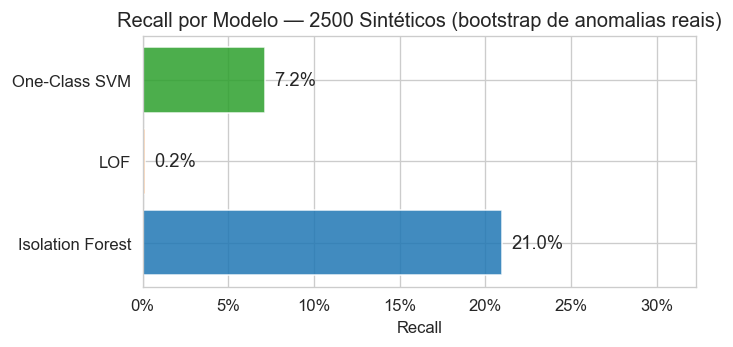

In [11]:
fig, ax = plt.subplots(figsize=(6, 3))

modelos  = ['Isolation Forest', 'LOF', 'One-Class SVM']
recalls  = [recall_if, recall_lof, recall_ocsvm]
cores    = ['#1f77b4', '#ff7f0e', '#2ca02c']

bars = ax.barh(modelos, recalls, color=cores, alpha=0.85)
for bar, val in zip(bars, recalls):
    ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2,
            f'{val:.1%}', va='center', fontsize=11)

ax.set_xlim(0, max(recalls) * 1.3 + 0.05)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title(f'Recall por Modelo — {len(sint)} Sintéticos (bootstrap de anomalias reais)', fontsize=12)
ax.set_xlabel('Recall')
plt.tight_layout()
plt.show()

#### 6.2 Distribuição dos Scores — Real vs. Sintético

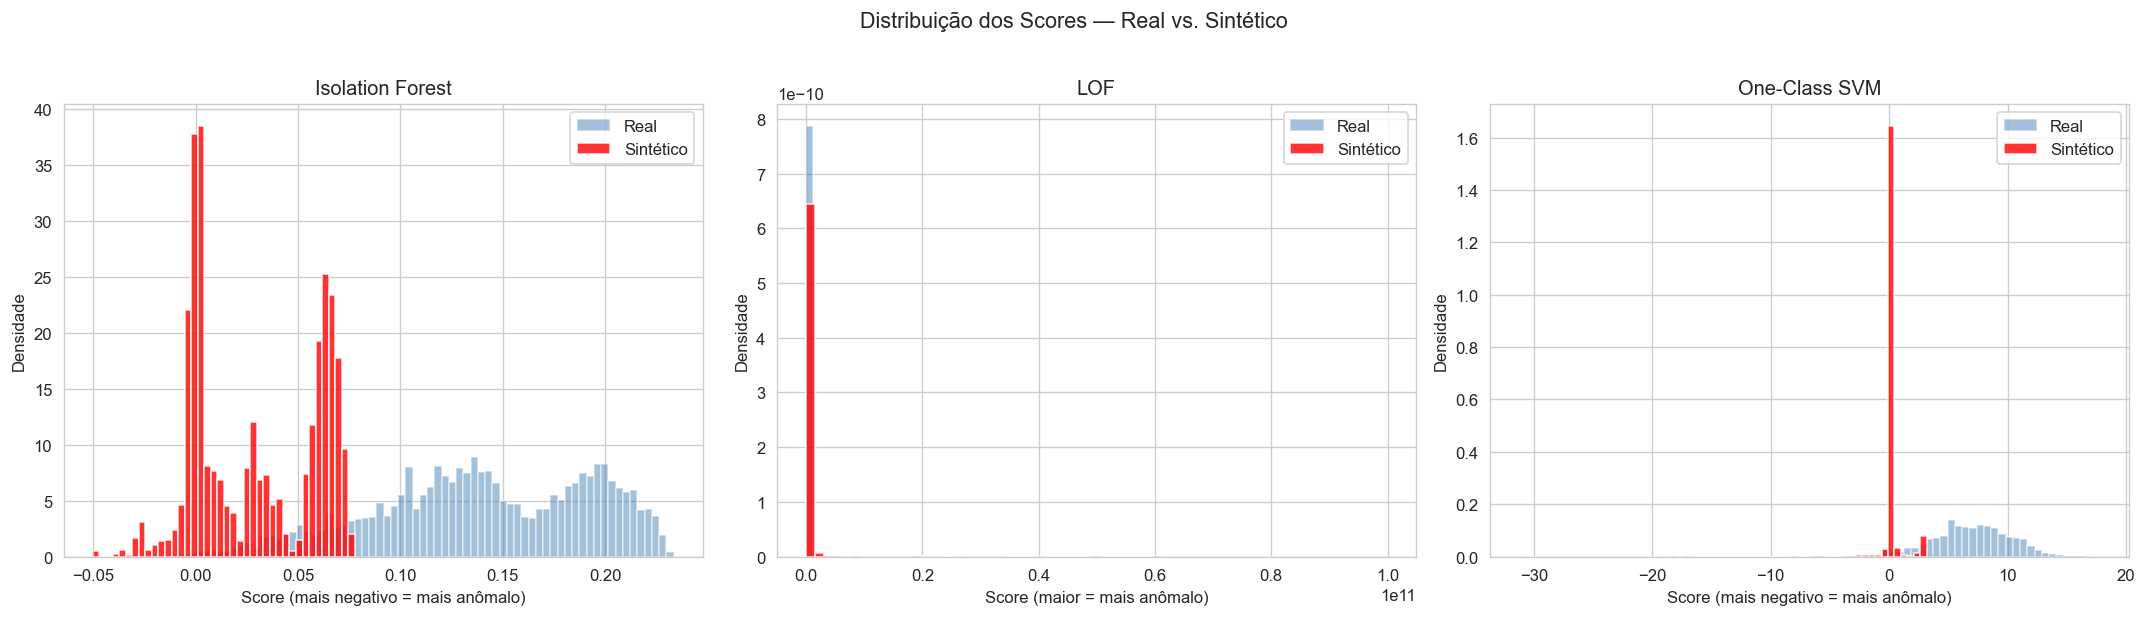

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

configs = [
    ('if_score',    'Isolation Forest',  'Score (mais negativo = mais anômalo)'),
    ('lof_score',   'LOF',               'Score (maior = mais anômalo)'),
    ('ocsvm_score', 'One-Class SVM',     'Score (mais negativo = mais anômalo)'),
]

for ax, (col, title, xlabel) in zip(axes, configs):
    real_scores = df_combined.loc[~df_combined['_sintetico'], col]
    sint_scores = df_combined.loc[ df_combined['_sintetico'], col]

    ax.hist(real_scores, bins=80, alpha=0.5, color='steelblue',
            density=True, label='Real')
    ax.hist(sint_scores, bins=40, alpha=0.8, color='red',
            density=True, label='Sintético')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Densidade')
    ax.legend()

plt.suptitle('Distribuição dos Scores — Real vs. Sintético', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

---
### 7. Exportação dos Resultados

In [13]:
df_recall.to_csv('data/output/recall_sinteticos.csv', index=False)
print('Salvo: data/output/recall_sinteticos.csv')

sint_export = df_combined[df_combined['_sintetico'] == True][[
    'if_score',    'if_label',
    'lof_score',   'lof_label',
    'ocsvm_score', 'ocsvm_label',
    'votos'
]].copy()
sint_export.to_csv('data/output/sinteticos_detalhado.csv', index=False)
print('Salvo: data/output/sinteticos_detalhado.csv')

print()
print('=== Resumo Final ===')
print(df_recall.to_string(index=False))

Salvo: data/output/recall_sinteticos.csv
Salvo: data/output/sinteticos_detalhado.csv

=== Resumo Final ===
              Modelo  Anomalias_detectadas  Recall
    Isolation Forest                   525  0.2100
Local Outlier Factor                     4  0.0016
       One-Class SVM                   179  0.0716


---
### 8. Comparação com o Ranking de Risco (NB09)

Onde os sintéticos cairiam no ranking real? Esta seção calcula o `score_combinado` para
os sintéticos usando a mesma metodologia do NB09 (MinMax nos 3 scores, média) e os
posiciona dentro da distribuição do ranking original.

In [14]:
from sklearn.preprocessing import MinMaxScaler

mms = MinMaxScaler()
df_combined['if_score_norm']    = mms.fit_transform(-df_combined[['if_score']])
df_combined['lof_score_norm']   = mms.fit_transform( df_combined[['lof_score']])
df_combined['ocsvm_score_norm'] = mms.fit_transform(-df_combined[['ocsvm_score']])

df_combined['score_combinado'] = df_combined[[
    'if_score_norm', 'lof_score_norm', 'ocsvm_score_norm'
]].mean(axis=1)

df_rank_full = df_combined.sort_values(
    ['votos', 'score_combinado'], ascending=[False, False]
).reset_index(drop=True)
df_rank_full['posicao'] = df_rank_full.index + 1

n_total      = len(df_rank_full)
sint_ranked  = df_rank_full[df_rank_full['_sintetico'] == True]

med_pos  = sint_ranked['posicao'].median()
min_pos  = sint_ranked['posicao'].min()
pct_med  = med_pos / n_total * 100
pct_min  = min_pos / n_total * 100

print(f'Total no ranking: {n_total}')
print(f'Sintéticos incluídos: {len(sint_ranked)}')
print()
print(f'Posição mediana dos sintéticos: {med_pos:.0f} / {n_total}  (top {pct_med:.1f}%)')
print(f'Melhor posição de um sintético: {min_pos:.0f} / {n_total}  (top {pct_min:.2f}%)')
print()

top1_pct  = int(n_total * 0.01)
top5_pct  = int(n_total * 0.05)
top10_pct = int(n_total * 0.10)

print(f'Sintéticos no top  1% ({top1_pct:>5} posições): {(sint_ranked["posicao"] <= top1_pct).sum()}')
print(f'Sintéticos no top  5% ({top5_pct:>5} posições): {(sint_ranked["posicao"] <= top5_pct).sum()}')
print(f'Sintéticos no top 10% ({top10_pct:>5} posições): {(sint_ranked["posicao"] <= top10_pct).sum()}')

Total no ranking: 77971
Sintéticos incluídos: 2500

Posição mediana dos sintéticos: 3254 / 77971  (top 4.2%)
Melhor posição de um sintético: 2 / 77971  (top 0.00%)

Sintéticos no top  1% (  779 posições): 459
Sintéticos no top  5% ( 3898 posições): 1413
Sintéticos no top 10% ( 7797 posições): 2405


#### 8.2 Distribuição de Posição por Perfil no Ranking

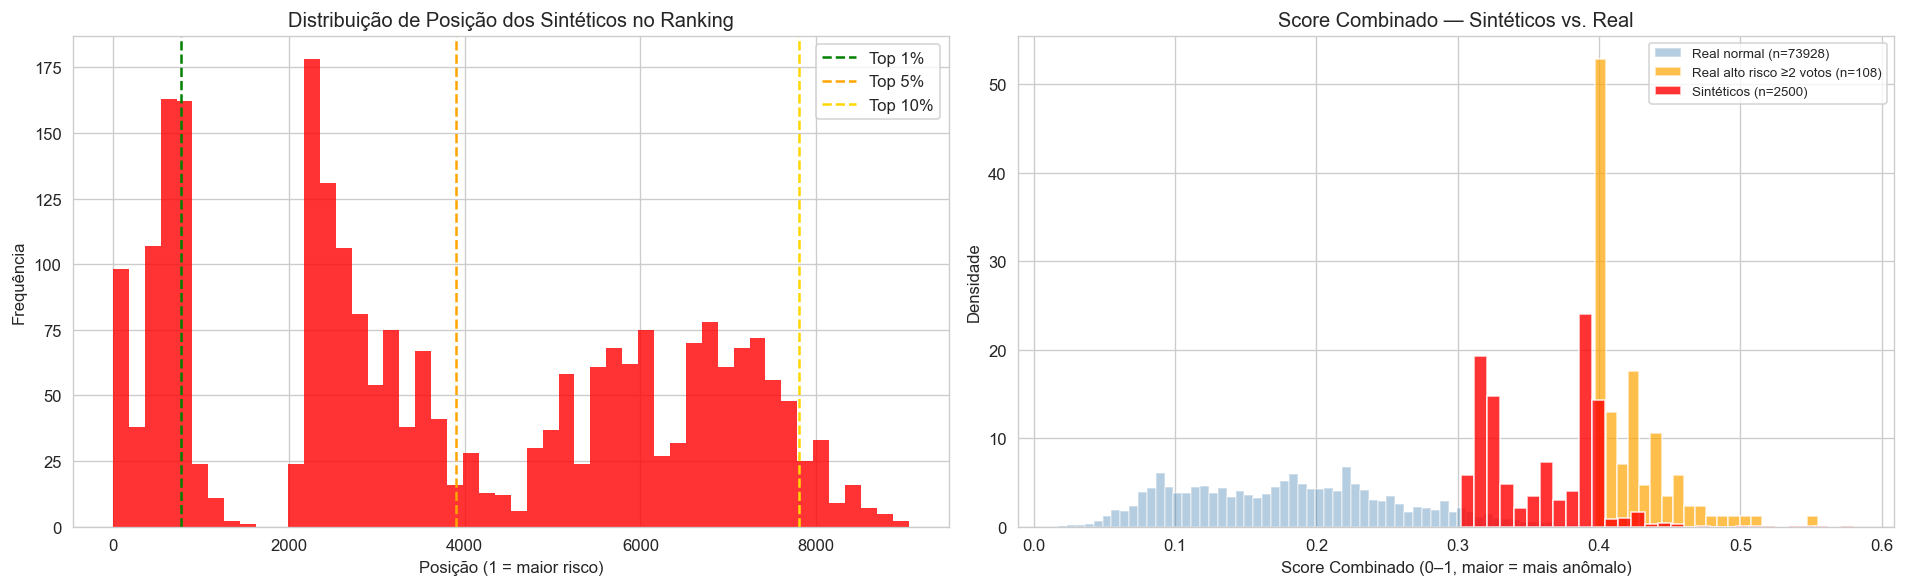

Figura salva em data/output/fig_ranking_sinteticos.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Histograma de posição no ranking ---
axes[0].hist(sint_ranked['posicao'], bins=50, color='red', alpha=0.8, edgecolor='none')
axes[0].axvline(n_total * 0.01, color='green',  linestyle='--', label='Top 1%')
axes[0].axvline(n_total * 0.05, color='orange', linestyle='--', label='Top 5%')
axes[0].axvline(n_total * 0.10, color='gold',   linestyle='--', label='Top 10%')
axes[0].set_title('Distribuição de Posição dos Sintéticos no Ranking')
axes[0].set_xlabel('Posição (1 = maior risco)')
axes[0].set_ylabel('Frequência')
axes[0].legend()

# --- Score combinado: sintéticos vs. real ---
real_alto   = df_rank_full[(~df_rank_full['_sintetico']) & (df_rank_full['votos'] >= 2)]
real_normal = df_rank_full[(~df_rank_full['_sintetico']) & (df_rank_full['votos'] == 0)]

axes[1].hist(real_normal['score_combinado'],  bins=60, alpha=0.4, color='steelblue',
             density=True, label=f'Real normal (n={len(real_normal)})')
axes[1].hist(real_alto['score_combinado'],    bins=20, alpha=0.7, color='orange',
             density=True, label=f'Real alto risco ≥2 votos (n={len(real_alto)})')
axes[1].hist(sint_ranked['score_combinado'],  bins=30, alpha=0.8, color='red',
             density=True, label=f'Sintéticos (n={len(sint_ranked)})')
axes[1].set_title('Score Combinado — Sintéticos vs. Real')
axes[1].set_xlabel('Score Combinado (0–1, maior = mais anômalo)')
axes[1].set_ylabel('Densidade')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('data/output/fig_ranking_sinteticos.png', bbox_inches='tight')
plt.show()
print('Figura salva em data/output/fig_ranking_sinteticos.png')

#### 8.3 Top-20 do Ranking Combinado — Quais são sintéticos?

In [16]:
top20 = df_rank_full.head(20)[[
    'posicao', '_sintetico', 'votos', 'score_combinado', 'desvio_item_estimado'
]].copy()
top20['origem'] = top20['_sintetico'].map({True: '🔴 SINTÉTICO', False: '🔵 real'})

n_sint_top20 = top20['_sintetico'].sum()
print(f'=== Top-20 do Ranking Combinado ===')
print(f'Sintéticos no top-20: {n_sint_top20} / 20\n')
print(top20[['posicao', 'origem', 'votos', 'score_combinado', 'desvio_item_estimado']].to_string(index=False))

=== Top-20 do Ranking Combinado ===
Sintéticos no top-20: 8 / 20

 posicao      origem  votos  score_combinado  desvio_item_estimado
       1      🔵 real      2         0.554683             -0.439577
       2 🔴 SINTÉTICO      2         0.552756             -0.422477
       3 🔴 SINTÉTICO      2         0.552334             -0.422104
       4 🔴 SINTÉTICO      2         0.522846             -0.487459
       5 🔴 SINTÉTICO      2         0.514292             -0.459662
       6 🔴 SINTÉTICO      2         0.513906             -0.456200
       7      🔵 real      2         0.512382             -0.452723
       8      🔵 real      2         0.505404              0.000000
       9      🔵 real      2         0.494195              0.000000
      10      🔵 real      2         0.489070             -0.279888
      11 🔴 SINTÉTICO      2         0.478152             -0.827240
      12      🔵 real      2         0.477513              0.000000
      13      🔵 real      2         0.473757             -0.899